# Identification baseline: what a PINN can tell you about an unknown parameter

> **Repository:** [PINNs-RL-PDE](https://github.com/josegarciav/PINNs-RL-PDE) · **Docs:** [Theory](https://josegarciav.github.io/PINNs-RL-PDE/theory/) · [Benchmarks](https://josegarciav.github.io/PINNs-RL-PDE/benchmarks/)

This notebook reviews the identification experiments of the v0.5 inverse-modelling core (roadmap item 2, paper P07). Each one asks a question about estimating a scalar PDE parameter from noisy observations with a PINN, and each is compared with the **Cramér–Rao bound**, the best any unbiased estimator can do from the same observations:

| Experiment | Question | Folder |
|---|---|---|
| F01 | Accuracy of the heat diffusivity vs noise and number of observations | `experiments/F01_heat_alpha_recovery` |
| F04 | Does the estimate depend on the initial guess? | `experiments/F04_initial_guess` |
| F05 | Fixed probes read densely in time vs random scatter | `experiments/F05_fixed_sensors` |
| F02 | Are two KdV coefficients jointly identifiable? | `experiments/F02_kdv_joint` |
| F03 | Burgers viscosity near the shock | `experiments/F03_burgers_nu` |
| F07 | Practical identifiability by profile likelihood | `experiments/F07_profile_likelihood` |

Every number below is computed here from the raw per-seed results in `experiments/<ID>/results/runs.json`, and every figure is re-rendered by the experiment's own `plot.py`. The README of each folder holds the same tables and the conclusions; this notebook shows them side by side and adds a few views the READMEs do not have. To regenerate the raw results, run the command at the top of each folder's README (each sweep takes 20 minutes to 3 hours on a laptop CPU).

The common setup, unless a section says otherwise: the catalogue entry `heat` of `pinnrl.CustomPDE` ($u_t = \alpha u_{xx}$, $\alpha = 0.1$) with `alpha` trainable and started at 5× the truth, a 4 × 64 tanh MLP, Adam at $10^{-3}$ for 5,000 steps, loss weights residual / BC / IC / data = 1 / 10 / 10 / 10, 10 seeds. A seed fixes the observation points, the noise draw and the initial weights.

## The problem, in symbols

A governing equation with parameters $\theta \in \mathbb{R}^p$,

$$
\mathcal{N}_\theta[u] = 0 \ \text{in } \Omega \times (0, T], \qquad \mathcal{B}[u] = g \ \text{on } \partial\Omega, \qquad u(\cdot, 0) = u_0,
$$

and $N$ noisy observations of its solution,

$$
y_i = u(x_i, t_i;\, \theta^\star) + \varepsilon_i, \qquad \varepsilon_i \sim \mathcal{N}(0, \sigma^2), \quad i = 1, \dots, N.
$$

The PINN inverse problem fits a network $u_w(x, t)$ and the parameters $\theta$ together by minimizing

$$
\mathcal{L}(w, \theta) \;=\; \lambda_r \,\frac{1}{N_r}\sum_{j} \big|\mathcal{N}_\theta[u_w](x_j, t_j)\big|^2
\;+\; \lambda_b \,\frac{1}{N_b}\sum_{j} \big|\mathcal{B}[u_w] - g\big|^2
\;+\; \lambda_0 \,\frac{1}{N_0}\sum_{j} \big|u_w(x_j, 0) - u_0(x_j)\big|^2
\;+\; \lambda_d \,\frac{1}{N}\sum_{i} \big|u_w(x_i, t_i) - y_i\big|^2 ,
$$

with weights $(\lambda_r, \lambda_b, \lambda_0, \lambda_d) = (1, 10, 10, 10)$ here. The parameters enter only through the residual term: the physics pins $u_w$ to the solution for the current $\theta$, the data term pulls that solution toward the measurements, and $\theta$ moves to reconcile the two. The estimate is $\hat\theta = \theta$ at the last step.

**What the estimate is compared with.** The sensitivity of the observations to the parameters is the Jacobian

$$
J_{ij} = \frac{\partial u(x_i, t_i;\, \theta)}{\partial \theta_j}, \qquad F = \frac{1}{\sigma^2}\, J^\top J \quad\text{(Fisher information)},
$$

and the Cramér–Rao inequality says that every unbiased estimator of $\theta$ from these $N$ observations has

$$
\operatorname{Cov}(\hat\theta) \;\succeq\; F^{-1}, \qquad\text{so}\qquad \operatorname{std}(\hat\theta_j) \;\ge\; \sqrt{(F^{-1})_{jj}} .
$$

Every table below puts the **spread of $\hat\theta$ across the 10 seeds** (each seed is a new noise draw) next to this bound. Spread equal to the bound means the PINN is an *efficient* estimator for that cell; spread above it means something other than the noise limits the estimate; a **bias** (a mean shifted from $\theta^\star$) is what the bound says nothing about, and is reported separately. The theory behind these statements is in the [Identifiability](https://josegarciav.github.io/PINNs-RL-PDE/theory/identifiability/) and [Bayesian view](https://josegarciav.github.io/PINNs-RL-PDE/theory/bayesian/) pages.

In [1]:
import json
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image, Markdown, display

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
EXP = ROOT / "experiments"
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 10})


def load(exp):
    """The raw runs of an experiment (every seed, every cell), or None if it has not been run."""
    path = EXP / exp / "results" / "runs.json"
    if not path.exists():
        display(Markdown(f"> **{exp} has no results yet.** Run `python experiments/{exp}/run.py` first."))
        return None
    return json.loads(path.read_text())


def figure(exp, png, script="plot.py"):
    """Re-render an experiment's figure from its raw results with its own plot script, then show it."""
    if not (EXP / exp / "results").exists():
        display(Markdown(f"> **{exp} has no results yet**, so its figure cannot be rendered."))
        return
    subprocess.run([sys.executable, str(EXP / exp / script)], check=True, capture_output=True)
    display(Image(filename=str(EXP / exp / "results" / png), width=1100))


def table(header, rows):
    """A Markdown table from a header list and rows of already formatted strings."""
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(str(c) for c in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))


def med_iqr(values):
    v = np.asarray(values, dtype=float)
    q25, q75 = np.percentile(v, [25, 75])
    return f"{np.median(v):.3f} [{q25:.3f}, {q75:.3f}]"


def readme(exp, section="Conclusion"):
    """Show one section of the experiment's README, so the notebook and the folder say the same thing."""
    text = (EXP / exp / "README.md").read_text()
    body = text.split(f"## {section}")[1].split("\n## ")[0] if f"## {section}" in text else ""
    display(Markdown(f"**{section} (from `experiments/{exp}/README.md`)**\n" + body))

## F01: accuracy vs noise and number of observations

**The equation.** $u_t = \alpha\, u_{xx}$ on $x \in [0, 1]$, $t \in [0, 1]$, with $u(x, 0) = \sin \pi x$ and $u(0, t) = u(1, t) = 0$. Its solution is the single decaying mode

$$
u(x, t;\, \alpha) = e^{-\alpha \pi^2 t} \sin \pi x, \qquad \alpha^\star = 0.1 ,
$$

so $u$ has amplitude 1 at $t = 0$ and $e^{-\pi^2/10} \approx 0.37$ at $t = 1$.

**Question.** How accurate is $\hat\alpha$ as a function of the noise $\sigma \in \{0, 0.01, 0.05, 0.1\}$ and the number of observations $N \in \{20, 50, 200, 1000\}$, at uniform random points of the domain?

**The bound.** The sensitivity has a closed form,

$$
\frac{\partial u}{\partial \alpha} = -\pi^2 t\, u(x, t;\, \alpha),
\qquad
F = \frac{\pi^4}{\sigma^2} \sum_{i=1}^{N} t_i^2\, u_i^2,
\qquad
\frac{\operatorname{std}(\hat\alpha)}{\alpha} \;\ge\; \frac{\sigma}{\alpha\, \pi^2 \sqrt{\sum_i t_i^2 u_i^2}} .
$$

For uniform random points $\mathbb{E}[t^2 u^2]$ is a fixed number, so the bound scales as $\sigma / \sqrt{N}$: ten times the noise costs a hundred times the observations. The information is largest where $t\,u$ is largest, at mid-domain and late times, a fact F05 uses.

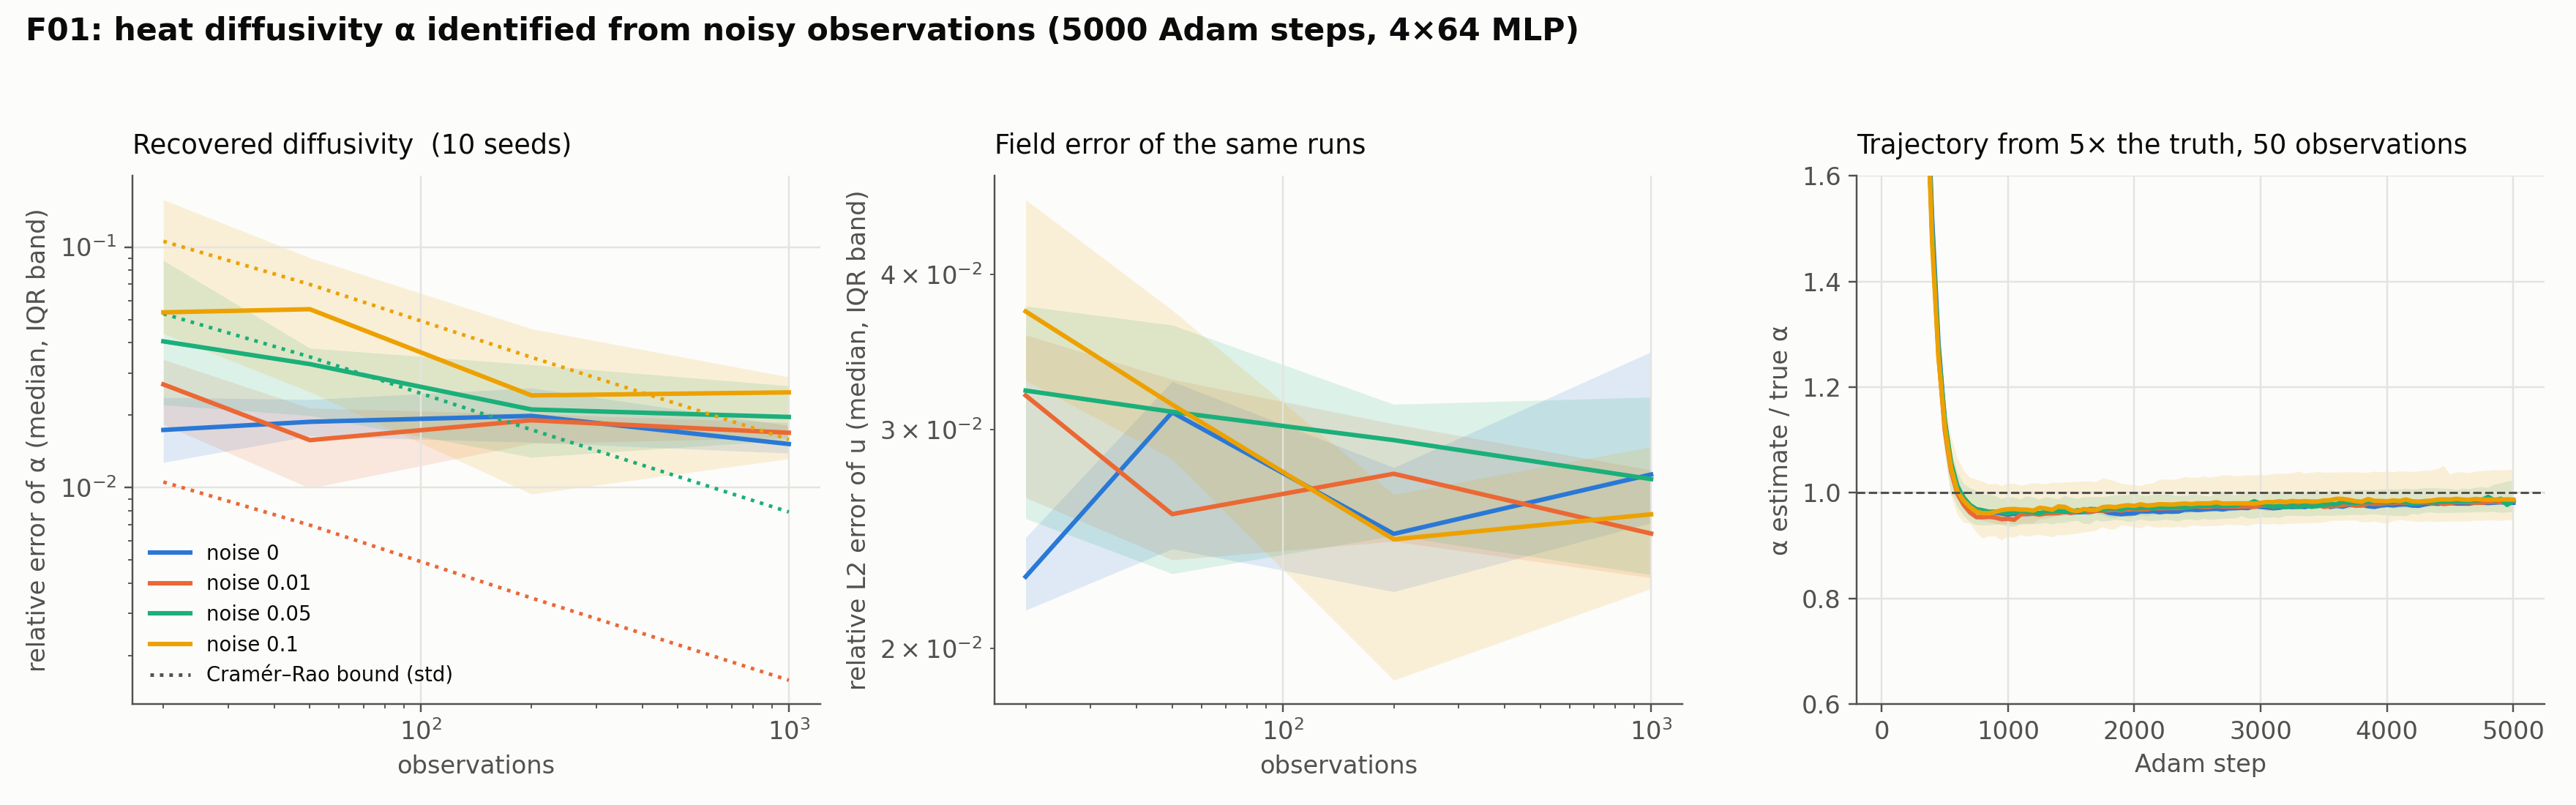

In [2]:
runs = load("F01_heat_alpha_recovery")
figure("F01_heat_alpha_recovery", "f01_heat_alpha.png")

In [3]:
NOISES = sorted({r["noise"] for r in runs})
N_OBS = sorted({r["n_obs"] for r in runs})
rows = []
for noise in NOISES:
    for n in N_OBS:
        sel = [r for r in runs if r["noise"] == noise and r["n_obs"] == n]
        a = np.array([r["alpha_hat"] for r in sel])
        rows.append([
            noise, n, med_iqr([r["rel_error"] for r in sel]),
            f"{a.std() / 0.1:.3f}", f"{np.median([r['crlb_rel_std'] for r in sel]):.3f}",
            f"{(a.mean() - 0.1) / 0.1:+.3f}", f"{np.median([r['l2_error'] for r in sel]):.3f}",
        ])
table(["noise σ", "N", "rel. error of α, median [IQR]", "spread across seeds", "Cramér–Rao bound", "mean bias", "rel. L2 of u"], rows)

| noise σ | N | rel. error of α, median [IQR] | spread across seeds | Cramér–Rao bound | mean bias | rel. L2 of u |
|---|---|---|---|---|---|---|
| 0.0 | 20 | 0.017 [0.013, 0.024] | 0.009 | 0.000 | -0.018 | 0.023 |
| 0.0 | 50 | 0.019 [0.016, 0.023] | 0.005 | 0.000 | -0.020 | 0.031 |
| 0.0 | 200 | 0.020 [0.015, 0.026] | 0.008 | 0.000 | -0.022 | 0.025 |
| 0.0 | 1000 | 0.015 [0.014, 0.018] | 0.009 | 0.000 | -0.019 | 0.028 |
| 0.01 | 20 | 0.027 [0.018, 0.034] | 0.015 | 0.011 | -0.029 | 0.032 |
| 0.01 | 50 | 0.016 [0.010, 0.021] | 0.007 | 0.007 | -0.015 | 0.026 |
| 0.01 | 200 | 0.019 [0.015, 0.020] | 0.005 | 0.003 | -0.019 | 0.028 |
| 0.01 | 1000 | 0.017 [0.016, 0.019] | 0.005 | 0.002 | -0.019 | 0.025 |
| 0.05 | 20 | 0.041 [0.022, 0.088] | 0.042 | 0.053 | -0.050 | 0.032 |
| 0.05 | 50 | 0.033 [0.020, 0.038] | 0.032 | 0.035 | -0.009 | 0.031 |
| 0.05 | 200 | 0.021 [0.013, 0.032] | 0.019 | 0.017 | -0.027 | 0.029 |
| 0.05 | 1000 | 0.020 [0.016, 0.027] | 0.007 | 0.008 | -0.021 | 0.027 |
| 0.1 | 20 | 0.054 [0.044, 0.157] | 0.077 | 0.106 | -0.090 | 0.037 |
| 0.1 | 50 | 0.055 [0.025, 0.090] | 0.065 | 0.070 | -0.002 | 0.031 |
| 0.1 | 200 | 0.024 [0.009, 0.046] | 0.037 | 0.035 | -0.038 | 0.024 |
| 0.1 | 1000 | 0.025 [0.013, 0.029] | 0.012 | 0.016 | -0.020 | 0.026 |

**Reading the table.** Two regimes. With clean or lightly noisy data the error is 1.5–2 % whatever $N$: it is a *bias* (every seed lands near 0.098) with a spread far below it, and the bound at 1,000 points is 0.2 %. That floor is the surrogate's own forward error absorbed by the parameter. Above the floor, at $\sigma \ge 0.05$, the spread across seeds tracks the bound.

The view below is not in the README: every cell's spread against its bound, on one plot. Points on the diagonal are cells where the PINN is an efficient estimator; points above it are where something other than the noise limits the estimate.

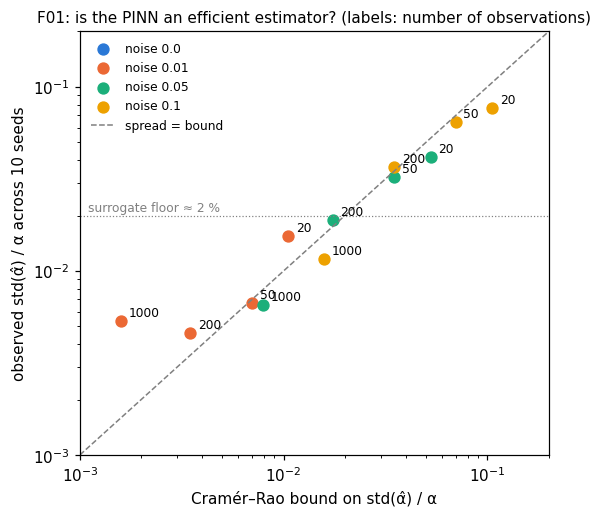

In [4]:
fig, ax = plt.subplots(figsize=(5.5, 5))
for noise, color in zip(NOISES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]):
    for n in N_OBS:
        sel = [r for r in runs if r["noise"] == noise and r["n_obs"] == n]
        spread = np.std([r["alpha_hat"] for r in sel]) / 0.1
        bound = np.median([r["crlb_rel_std"] for r in sel])
        ax.scatter(max(bound, 1e-4), spread, color=color, s=50, label=f"noise {noise}" if n == N_OBS[0] else None)
        ax.annotate(str(n), (max(bound, 1e-4), spread), textcoords="offset points", xytext=(5, 3), fontsize=8)
lim = [1e-3, 0.2]
ax.plot(lim, lim, "--", color="gray", linewidth=1, label="spread = bound")
ax.axhline(0.02, color="gray", linewidth=0.8, linestyle=":")
ax.text(1.1e-3, 0.021, "surrogate floor ≈ 2 %", fontsize=8, color="gray")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("Cramér–Rao bound on std(α̂) / α"); ax.set_ylabel("observed std(α̂) / α across 10 seeds")
ax.set_title("F01: is the PINN an efficient estimator? (labels: number of observations)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.show()

**Trajectories.** Each run records $\hat\alpha$ every 50 steps. Pick a cell to see how the estimate moves from the 5× start; with few noisy points some seeds never settle.

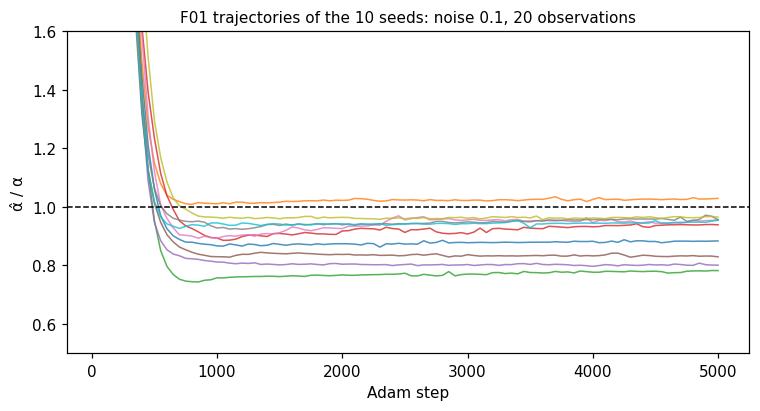

In [5]:
noise, n = 0.1, 20  # change to any cell of the grid
sel = [r for r in runs if r["noise"] == noise and r["n_obs"] == n]
steps = np.arange(1, len(sel[0]["trajectory"]) + 1) * 50
fig, ax = plt.subplots(figsize=(8, 3.8))
for r in sel:
    ax.plot(steps, np.array(r["trajectory"]) / 0.1, linewidth=1, alpha=0.8)
ax.axhline(1, color="black", linestyle="--", linewidth=1)
ax.set_ylim(0.5, 1.6); ax.set_xlabel("Adam step"); ax.set_ylabel("α̂ / α")
ax.set_title(f"F01 trajectories of the 10 seeds: noise {noise}, {n} observations", fontsize=10)
plt.show()

In [6]:
readme("F01_heat_alpha_recovery")

**Conclusion (from `experiments/F01_heat_alpha_recovery/README.md`)**


1. **The error has two regimes.** With clean or lightly noisy data ($\sigma \le 0.01$) the error of $\hat\alpha$ is 1.5–2 % whatever the number of observations, from 20 to 1,000. It is a **bias** (every seed lands at $\hat\alpha \approx 0.098$), not scatter: the spread across seeds is 0.5–0.9 %. The data carry far more information than that (the Cramér–Rao bound reaches 0.2 % at 1,000 points), so the floor is the PINN's own: the surrogate's field error of 2–3 % is absorbed by $\alpha$. More data cannot fix this; a more accurate forward solve can (a longer or two-stage training, L-BFGS, hard boundary constraints).
2. **Above the floor the estimator is close to efficient.** For $\sigma \ge 0.05$ the spread of $\hat\alpha$ across seeds matches the Cramér–Rao bound computed from the same observation points to within about 20 % in 7 of 8 cells (e.g. 0.065 vs 0.070 at $\sigma = 0.1$, $N = 50$; 0.012 vs 0.016 at $N = 1,000$). The $\sigma / \sqrt{N}$ law holds, so the Fisher information predicts how many sensors a given accuracy needs. This is the empirical justification for building the conditioning diagnostics of v0.5 on the sensitivity Jacobian (K01).
3. **Few noisy points bias the estimate low.** At $N = 20$ the mean bias grows with noise (−3 %, −5 %, −9 %) and the IQR becomes skewed, with a heavy tail toward small $\alpha$ (one seed at 0.078, a 22 % error, for $\sigma = 0.1$). A smoother field fits noisy points as well as a sharper one and has a smaller residual, so the physics loss pulls toward slower diffusion. The fixed data weight of 10 does not account for the noise level, which is what K39 (likelihood weighting, $1/\sigma^2$) tests.
4. **The field error does not predict the parameter error.** The relative L2 error of $u$ is 2–4 % in every cell, while the median error of $\alpha$ spans 1.5–5.5 % and single seeds reach 22 %. Reporting the field error alone, as most PINN inverse-problem papers do, says little about the identified physics.

**Consequences for the backlog:**
- The 2 % floor is a forward-accuracy problem: run F01 again after D01/D02 (learning-rate decay, L-BFGS finish) and report the floor against the forward error.
- K01 (Fisher information by autograd) can be validated against the closed-form bound used here before it is applied to problems without one.
- K39 is next in the F track after F02–F05: the low bias at small $N$ and large $\sigma$ is the signature of a misweighted data term.
- F04 (initial-guess sensitivity) can start from this script; the trajectories suggest 5× is benign for the heat equation.


## F04: does the estimate depend on the initial guess?

**The question in symbols.** The loss $\mathcal{L}(w, \theta)$ is not convex, so the optimizer may stop at a local minimum that depends on the starting point $(w_0, \alpha_0)$. The *basin of attraction* of the truth is the set of $\alpha_0$ from which $\hat\alpha \to \alpha^\star$. Here $\alpha_0 = f\,\alpha^\star$ for ten factors $f \in [0.1, 10]$, spaced logarithmically.

**Setup.** One data set per seed (200 observations, noise 0.05, the F01 cell whose bound, 1.7 %, is close to the surrogate floor), and the same $w_0$ for the ten starts of a seed, so the comparison is paired: the only thing that changes across a row is $\alpha_0$.

**A mechanical bound on speed.** Adam moves each parameter by at most about the learning rate $\eta = 10^{-3}$ per step, so from $\alpha_0 = 0.01$ the estimate needs at least $(0.1 - 0.01)/\eta = 90$ steps to reach the truth and from $\alpha_0 = 1.0$ at least $900$. The *settling step* reported below is the first step after which $|\hat\alpha - \alpha^\star| / \alpha^\star$ stays below 5 %.

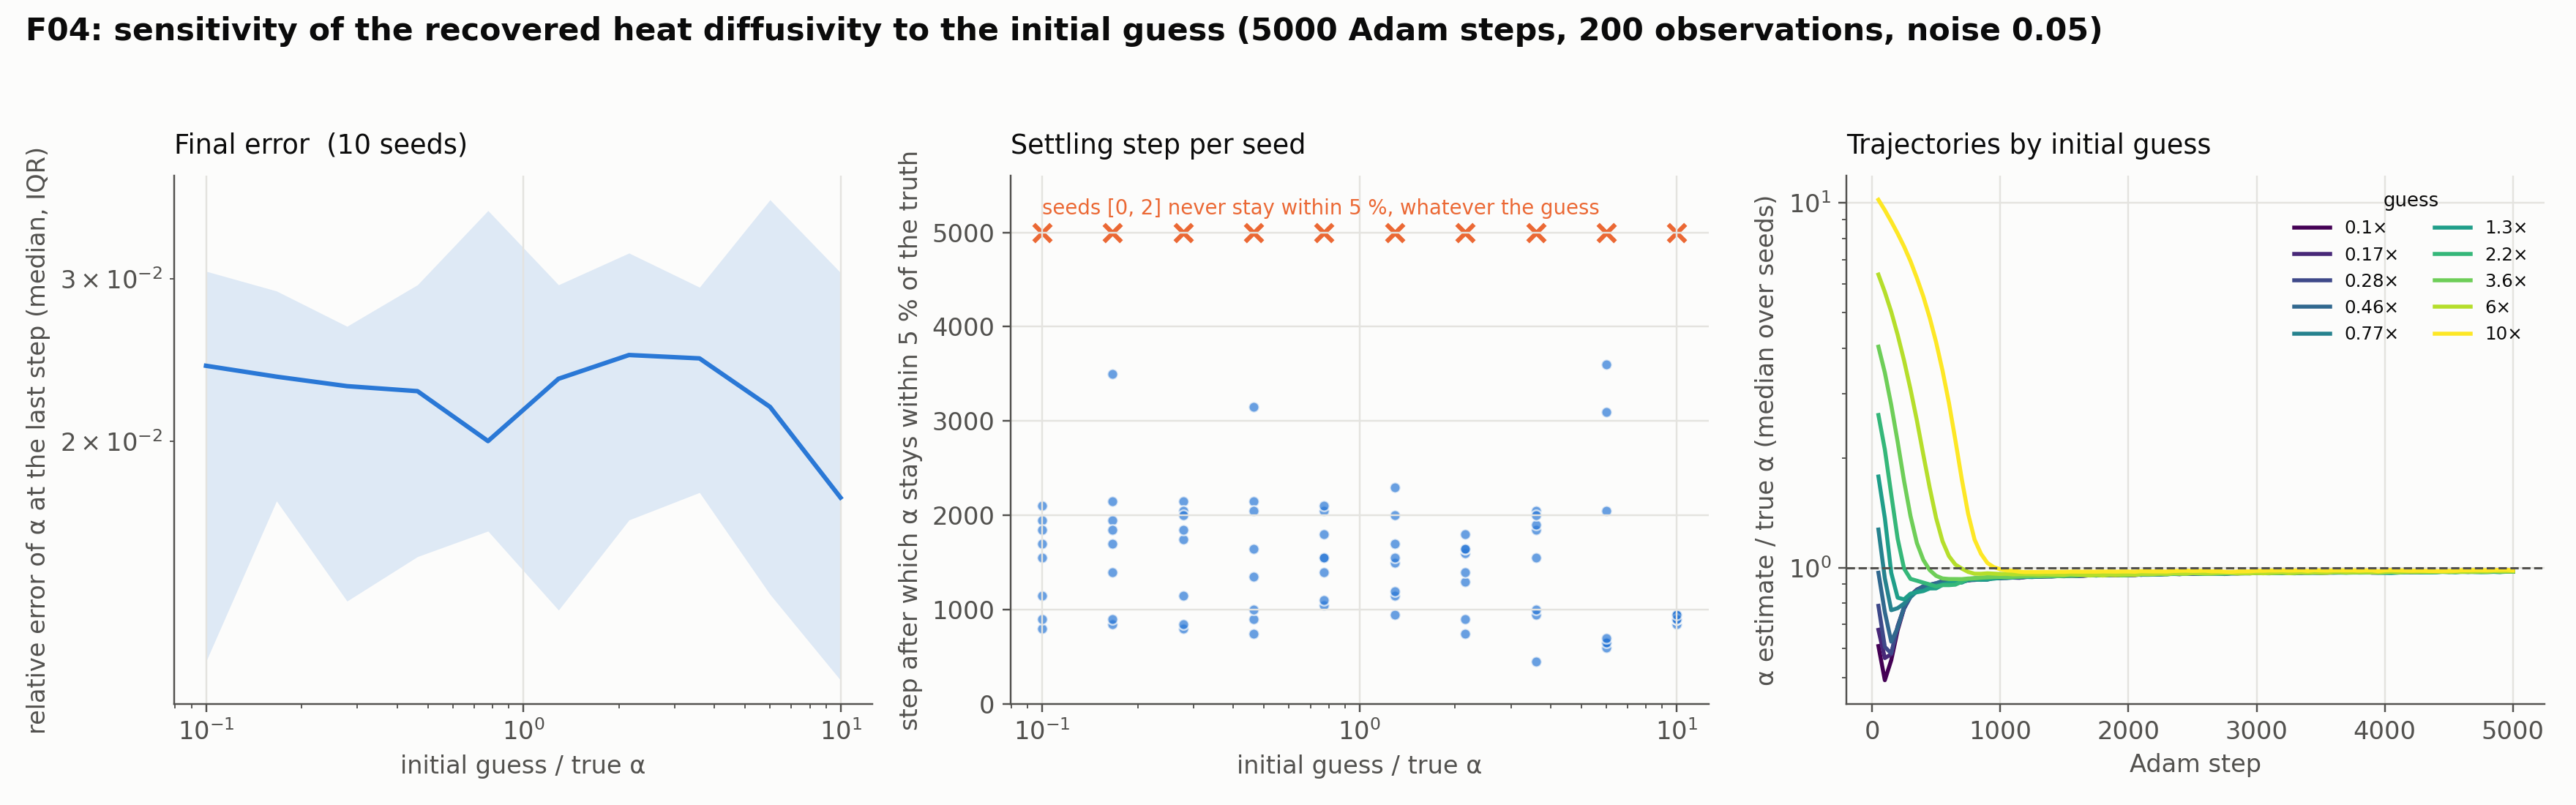

In [7]:
runs = load("F04_initial_guess")
figure("F04_initial_guess", "f04_initial_guess.png")

In [8]:
factors = sorted({r["guess_factor"] for r in runs})
rows = []
for f in factors:
    sel = [r for r in runs if r["guess_factor"] == f]
    a = np.array([r["alpha_hat"] for r in sel])
    settled = [r["settle_step"] for r in sel if r["settle_step"] is not None]
    rows.append([f"{f * 0.1:.3f}", f"{f:.2g}×", med_iqr([r["rel_error"] for r in sel]), f"{a.std() / 0.1:.3f}",
                 f"{np.median(settled):.0f}" if settled else "–", len(sel) - len(settled)])
table(["guess", "guess / α", "rel. error of α, median [IQR]", "spread across seeds", "settling step (median)", "never settle"], rows)

seeds = sorted({r["seed"] for r in runs})
across_seeds = np.median([np.std([r["alpha_hat"] for r in runs if r["guess_factor"] == f]) / 0.1 for f in factors])
across_guesses = np.median([np.std([r["alpha_hat"] for r in runs if r["seed"] == s]) / 0.1 for s in seeds])
table(["", "spread of α̂ (relative)"], [["across the 10 seeds at a fixed guess (median over guesses)", f"{across_seeds:.3f}"],
                                       ["across the 10 guesses at a fixed seed (median over seeds)", f"{across_guesses:.3f}"]])

| guess | guess / α | rel. error of α, median [IQR] | spread across seeds | settling step (median) | never settle |
|---|---|---|---|---|---|
| 0.010 | 0.1× | 0.024 [0.012, 0.031] | 0.020 | 1625 | 2 |
| 0.017 | 0.17× | 0.023 [0.017, 0.029] | 0.018 | 1775 | 2 |
| 0.028 | 0.28× | 0.023 [0.013, 0.027] | 0.018 | 1800 | 2 |
| 0.046 | 0.46× | 0.023 [0.015, 0.030] | 0.018 | 1500 | 2 |
| 0.077 | 0.77× | 0.020 [0.016, 0.036] | 0.018 | 1550 | 2 |
| 0.129 | 1.3× | 0.023 [0.013, 0.030] | 0.019 | 1525 | 2 |
| 0.215 | 2.2× | 0.025 [0.016, 0.032] | 0.018 | 1500 | 2 |
| 0.359 | 3.6× | 0.025 [0.018, 0.029] | 0.017 | 1700 | 2 |
| 0.599 | 6× | 0.022 [0.014, 0.037] | 0.018 | 675 | 2 |
| 1.000 | 10× | 0.017 [0.011, 0.030] | 0.019 | 900 | 2 |

|  | spread of α̂ (relative) |
|---|---|
| across the 10 seeds at a fixed guess (median over guesses) | 0.018 |
| across the 10 guesses at a fixed seed (median over seeds) | 0.003 |

**A view per seed.** The decisive check is paired: for each data set, where do the ten starts end? Each column below is one seed; the dots are its ten final estimates. If the start mattered the dots would scatter vertically; they stack.

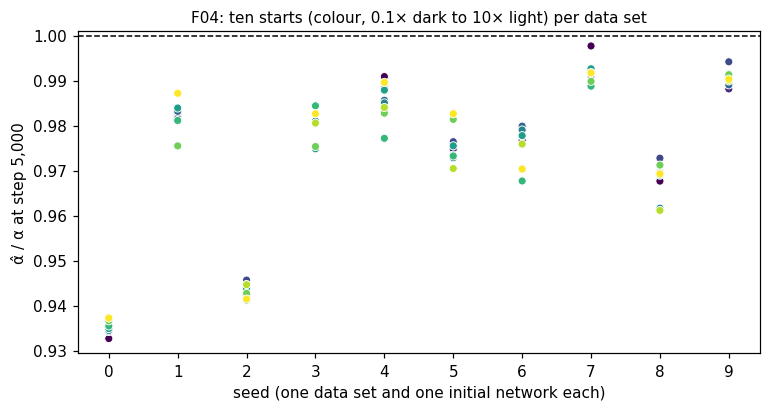

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.8))
cmap = plt.get_cmap("viridis")
for s in seeds:
    sel = sorted([r for r in runs if r["seed"] == s], key=lambda r: r["guess_factor"])
    ax.scatter([s] * len(sel), [r["alpha_hat"] / 0.1 for r in sel], c=[cmap(i / 9) for i in range(len(sel))], s=28, edgecolors="white", linewidths=0.6)
ax.axhline(1, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("seed (one data set and one initial network each)"); ax.set_ylabel("α̂ / α at step 5,000")
ax.set_title("F04: ten starts (colour, 0.1× dark to 10× light) per data set", fontsize=10)
ax.set_xticks(seeds)
plt.show()

In [10]:
readme("F04_initial_guess")

**Conclusion (from `experiments/F04_initial_guess/README.md`)**


1. **The estimate does not depend on where it starts.** For a given data set, the ten starting values from 0.1× to 10× the truth land within 0.3 % of each other (median range 1.1 %), six times less than the spread the data and the network initialization produce across seeds (1.8 %). The basin of attraction for the heat diffusivity covers at least two decades around the truth, so a poor prior is harmless here. K30 (basin of attraction) can start from a harder problem.
2. **The seeds that fail, fail for every guess.** Seeds 0 and 2 end 5–7 % low whatever the start, which identifies the noise realization of their 200 observations, not the optimizer, as the cause. The F01 finding stands: at this noise level the error is dominated by the data and the surrogate's bias, and an initial-guess sweep is not a way to detect or fix it.
3. **Far starts are not slower.** Starting at 6× or 10× the truth settles in 675–900 steps, sooner than starts near the truth (about 1,500). The early transient of the network, not the distance of the guess, decides when $\hat\alpha$ stops moving: a start far above the truth arrives from one side after the field has formed, while a start near the truth is dragged around while the field is still wrong. Adam's per-step cap of about the learning rate sets the lower bound (90 steps from 0.01, 900 from 1.0), which is visible in the trajectories.

**Consequences for the backlog:**
- F04 closes for scalar heat identification. The remaining question about starting points belongs to problems with several parameters or non-convex profiles (F02, F07, K30).
- A sweep over initial guesses is not a substitute for a noise-aware data weight (K39) or for repeating the fit on resampled data (F06).


## F05: fixed probes vs random scatter

**Plant-like data.** A plant does not scatter sensors at random in space-time: it has a few probes at fixed positions $x_p$, read at regular times. With $n_s$ probes at $x_p = p / (n_s + 1)$, $p = 1, \dots, n_s$, and $m = 200 / n_s$ readings each at $t_j = (j + \tfrac12) / m$, the data set has the same size as the 200-point random scatter but a different Fisher information,

$$
F_{\text{layout}} = \frac{\pi^4}{\sigma^2} \sum_{p=1}^{n_s} \sin^2(\pi x_p) \sum_{j=1}^{m} t_j^2\, e^{-2\alpha \pi^2 t_j} ,
$$

which factorizes into a spatial weight $\sin^2 \pi x_p$ (largest at the centre, zero at the walls) and a temporal weight $t^2 e^{-2\alpha\pi^2 t}$ (largest at $t = 1/(\alpha\pi^2) \approx 1$ for $\alpha = 0.1$). The bound therefore ranks the layouts before any training: a probe at $x = 0.5$ carries the most information per reading, and a probe at $x = 1/9$ carries $\sin^2(\pi/9) \approx 0.12$ of it.

**Setup.** Layouts: random scatter, or $n_s \in \{1, 2, 4, 8\}$ probes; noise 0.01, 0.05 and 0.1; otherwise as F01.

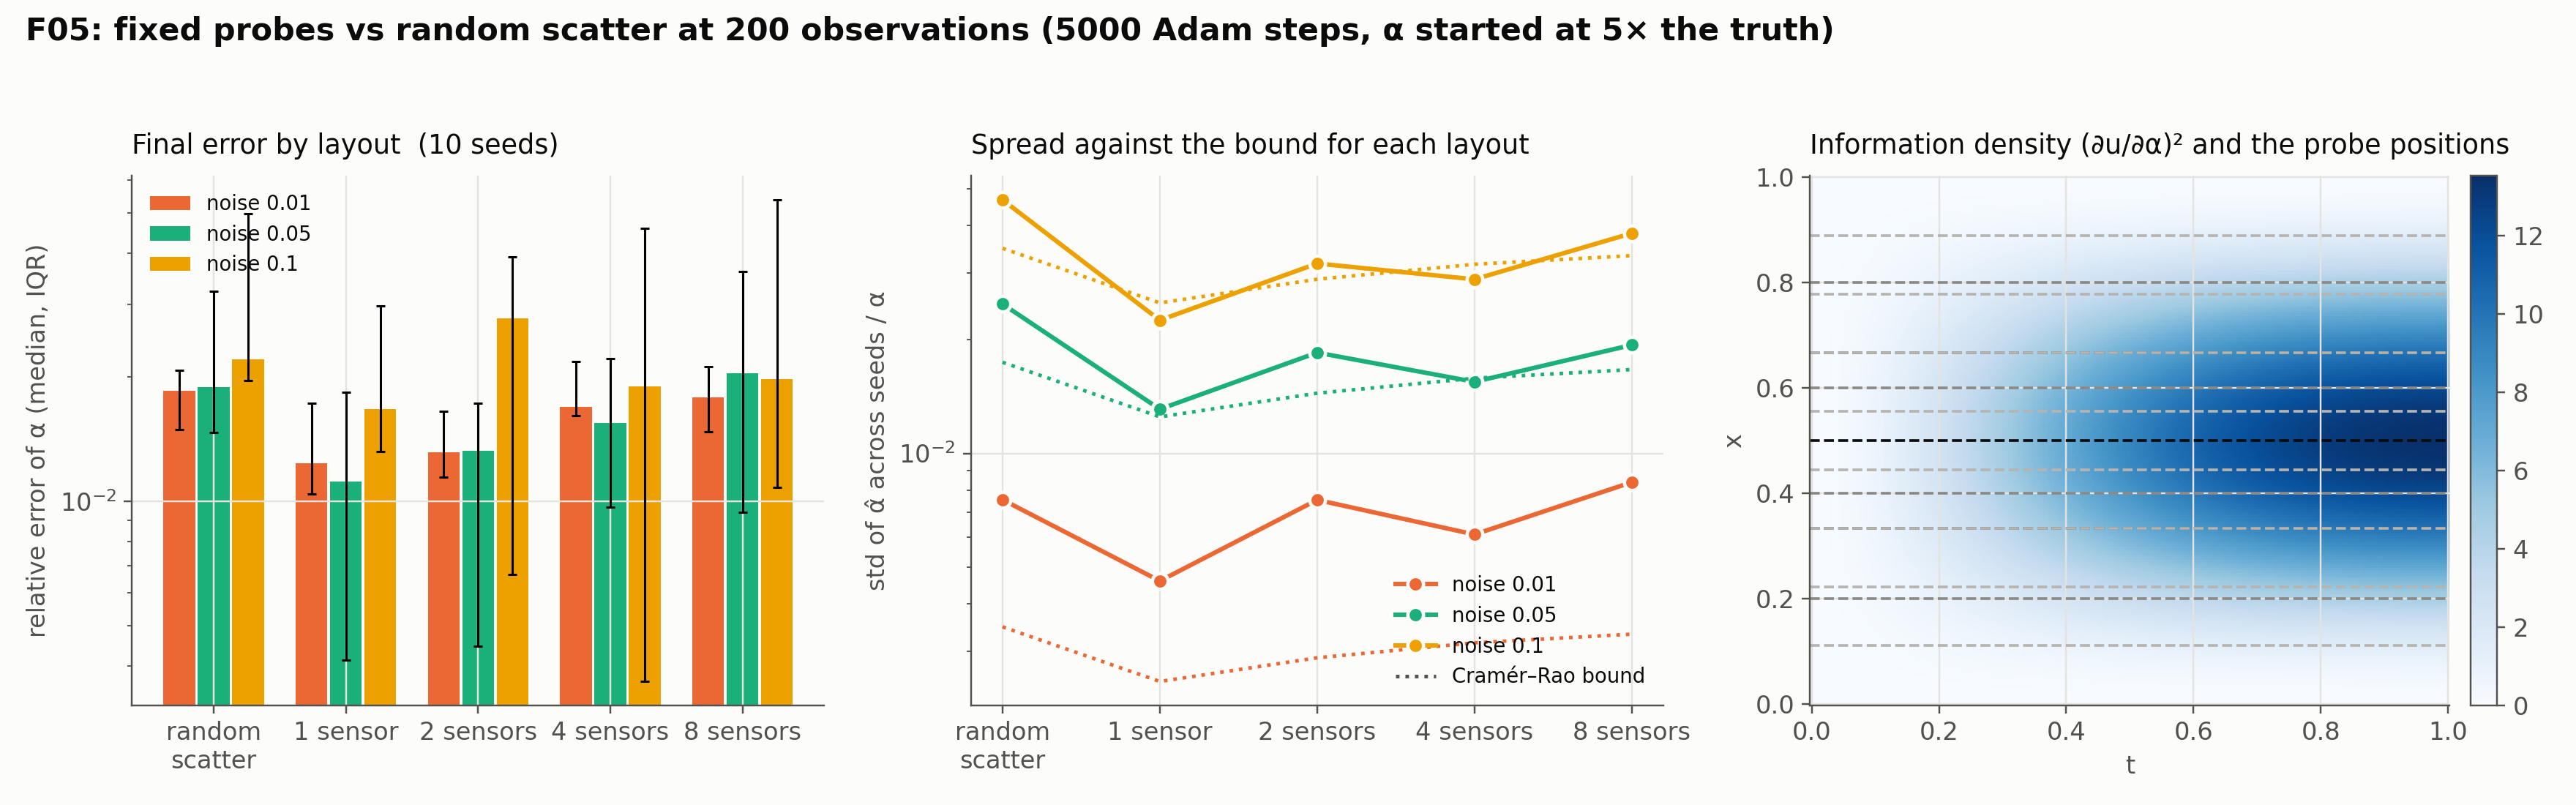

In [11]:
runs = load("F05_fixed_sensors")
figure("F05_fixed_sensors", "f05_fixed_sensors.png")

In [12]:
LAYOUTS = ["random", "1", "2", "4", "8"]
rows = []
for noise in sorted({r["noise"] for r in runs}):
    for layout in LAYOUTS:
        sel = [r for r in runs if r["noise"] == noise and r["layout"] == layout]
        a = np.array([r["alpha_hat"] for r in sel])
        rows.append([noise, "random scatter" if layout == "random" else f"{layout} probe(s)", med_iqr([r["rel_error"] for r in sel]),
                     f"{a.std() / 0.1:.3f}", f"{np.median([r['crlb_rel_std'] for r in sel]):.3f}", f"{(a.mean() - 0.1) / 0.1:+.3f}"])
table(["noise σ", "layout", "rel. error of α, median [IQR]", "spread across seeds", "Cramér–Rao bound", "mean bias"], rows)

| noise σ | layout | rel. error of α, median [IQR] | spread across seeds | Cramér–Rao bound | mean bias |
|---|---|---|---|---|---|
| 0.01 | random scatter | 0.019 [0.015, 0.021] | 0.008 | 0.003 | -0.019 |
| 0.01 | 1 probe(s) | 0.012 [0.010, 0.017] | 0.005 | 0.002 | -0.014 |
| 0.01 | 2 probe(s) | 0.013 [0.011, 0.017] | 0.008 | 0.003 | -0.016 |
| 0.01 | 4 probe(s) | 0.017 [0.016, 0.022] | 0.006 | 0.003 | -0.019 |
| 0.01 | 8 probe(s) | 0.018 [0.015, 0.021] | 0.008 | 0.003 | -0.019 |
| 0.05 | random scatter | 0.019 [0.015, 0.032] | 0.025 | 0.017 | -0.022 |
| 0.05 | 1 probe(s) | 0.011 [0.004, 0.018] | 0.013 | 0.012 | -0.012 |
| 0.05 | 2 probe(s) | 0.013 [0.004, 0.017] | 0.018 | 0.014 | -0.010 |
| 0.05 | 4 probe(s) | 0.015 [0.010, 0.022] | 0.015 | 0.016 | -0.014 |
| 0.05 | 8 probe(s) | 0.020 [0.009, 0.036] | 0.019 | 0.017 | -0.020 |
| 0.1 | random scatter | 0.022 [0.020, 0.050] | 0.047 | 0.035 | -0.024 |
| 0.1 | 1 probe(s) | 0.017 [0.013, 0.030] | 0.022 | 0.025 | -0.009 |
| 0.1 | 2 probe(s) | 0.028 [0.007, 0.039] | 0.032 | 0.029 | -0.007 |
| 0.1 | 4 probe(s) | 0.019 [0.004, 0.046] | 0.029 | 0.032 | -0.013 |
| 0.1 | 8 probe(s) | 0.020 [0.011, 0.054] | 0.038 | 0.033 | -0.020 |

**Where the information is.** The bound of a layout is $\sigma / \sqrt{\sum_i (\pi^2 t_i u_i)^2}$ over its 200 points. Computing it for a single probe at every position $x_p$ shows why one probe at the centre beats the scatter, and what an off-centre probe costs. This uses `pinnrl.analysis.closed_form_bound`, the same function the experiments use.

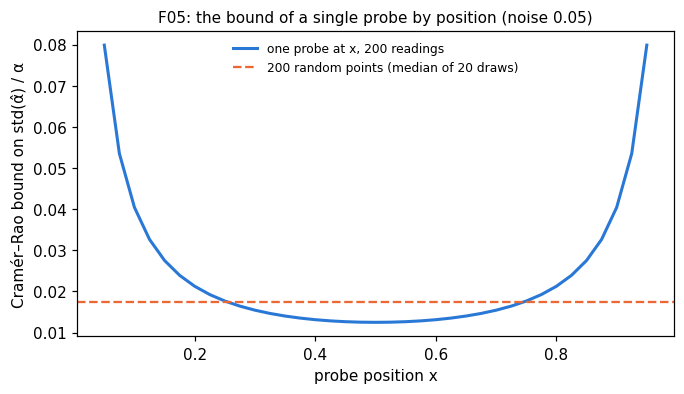

In [13]:
import torch
from pinnrl.analysis import closed_form_bound
from pinnrl.pdes.catalog import from_catalog

pde = from_catalog("heat")
positions = np.linspace(0.05, 0.95, 37)
times = (torch.arange(200, dtype=torch.float32) + 0.5)[:, None] / 200
bounds = [closed_form_bound(pde, ["alpha"], torch.full((200, 1), float(p)), times, 0.05).relative_std({"alpha": 0.1})["alpha"] for p in positions]
gen = torch.Generator().manual_seed(0)
scatter = np.median([closed_form_bound(pde, ["alpha"], torch.rand(200, 1, generator=gen), torch.rand(200, 1, generator=gen), 0.05).relative_std({"alpha": 0.1})["alpha"] for _ in range(20)])
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(positions, bounds, color="#2a78d6", linewidth=2, label="one probe at x, 200 readings")
ax.axhline(scatter, color="#eb6834", linestyle="--", label="200 random points (median of 20 draws)")
ax.set_xlabel("probe position x"); ax.set_ylabel("Cramér–Rao bound on std(α̂) / α"); ax.set_title("F05: the bound of a single probe by position (noise 0.05)", fontsize=10)
ax.legend(frameon=False, fontsize=8)
plt.show()

In [14]:
readme("F05_fixed_sensors")

**Conclusion (from `experiments/F05_fixed_sensors/README.md`)**


1. **One well-placed probe beats 200 scattered points.** A single probe at $x = 0.5$ read at 200 times has a Cramér–Rao bound of 1.2 % at $\sigma = 0.05$ against 1.7 % for random scatter, and the PINN delivers it: median error 1.1 % vs 1.9 %, spread 1.3 % vs 2.5 %. The information about $\alpha$, $(\partial u/\partial\alpha)^2 = (\pi^2 t\, u)^2$, is concentrated at mid-domain and late times (right panel), where the probe sits and the scatter mostly is not.
2. **More probes at a fixed data count are slightly worse, and the bound says so.** Spreading 200 readings over 8 positions puts the outer probes at $x = 1/9$ and $8/9$, where $u$ is small and the readings carry little information; the bound rises from 1.2 % (1 probe) to 1.7 % (8 probes) and the measured spread follows (1.3 % to 1.9 %). Sensor placement is a question the Fisher information answers before any training, which is the basis of K02 and of the measurement-design work (P24).
3. **The estimator remains near-efficient with plant-like data.** At $\sigma \ge 0.05$ the spread across seeds is within 30 % of the bound in 8 of the 10 cells and within 50 % in all of them; the five low-noise cells sit 2–3× above a bound of 0.2–0.3 %, where the surrogate's 2 % floor dominates. Regular time sampling at fixed positions changes nothing in that respect.
4. **Dense time series reduce the bias.** The low-noise bias is −1.4 % with one probe against −1.9 % with scatter, and at $\sigma = 0.1$ it is −0.9 % against −2.4 %. Many readings along one decay curve pin the rate; scattered points pin the field. The surrogate floor found in F01 is therefore partly a property of the data layout, not only of the network.

**Consequences for the backlog:**
- K02 (sensor placement from the Fisher information) can use the bound as its design criterion; this experiment is its first validation point.
- F05 settles the data mode for the process twins (J-track): fixed probes with dense time series are the right abstraction for `pinnrl`'s sensor operators (roadmap v0.6).
- The bias reduction with dense time series should be checked on F03 (Burgers) where the information sits in the shock rather than at late times.


## F02: joint identification of the KdV coefficients

**The equation.** The Korteweg–de Vries equation with two coefficients,

$$
u_t + \alpha\, u\, u_x + \beta\, u_{xxx} = 0, \qquad x \in [-15, 15],\ t \in [0, 2],
$$

has the travelling soliton of unit speed

$$
u(x, t;\, \alpha, \beta) = \frac{3}{\alpha}\, \operatorname{sech}^2\!\Big( \tfrac{1}{2}\sqrt{1/\beta}\,(x - t) \Big), \qquad (\alpha^\star, \beta^\star) = (6, 1),
$$

so the **amplitude** is $3/\alpha$ and the **width** is $\propto \sqrt{\beta}$. Both are visible in the data, which makes the pair structurally identifiable (no scaling of $(\alpha, \beta)$ leaves the observations unchanged once the speed is fixed by the data). But a taller soliton is also a narrower one for the equation, so the data *correlate* the two estimates; how strongly is what the 2 × 2 Fisher matrix says.

**The bound in two dimensions.** With $J = [\partial u/\partial\alpha,\ \partial u/\partial\beta]$ evaluated at the observation points,

$$
F = \frac{1}{\sigma^2} J^\top J \in \mathbb{R}^{2\times 2}, \qquad
F^{-1} = \begin{pmatrix} s_\alpha^2 & \rho\, s_\alpha s_\beta \ \rho\, s_\alpha s_\beta & s_\beta^2 \end{pmatrix},
$$

gives the two standard deviations, their correlation $\rho$, and the condition number $\kappa(F) = \lambda_{\max}/\lambda_{\min}$, whose eigenvectors are the well- and poorly-determined combinations of $(\alpha, \beta)$. The orange ellipse in the figure is the $2\sigma$ contour of $F^{-1}$: ten unbiased, efficient estimates should scatter inside it with correlation $\rho$.

**Setup.** Observations at uniform random points of the whole domain (most of them in the flat tails of the soliton), noise 0.01 and 0.05, $N \in \{50, 200, 1000\}$, started at $(4, 1.5)$, 8,000 steps, 10 seeds.

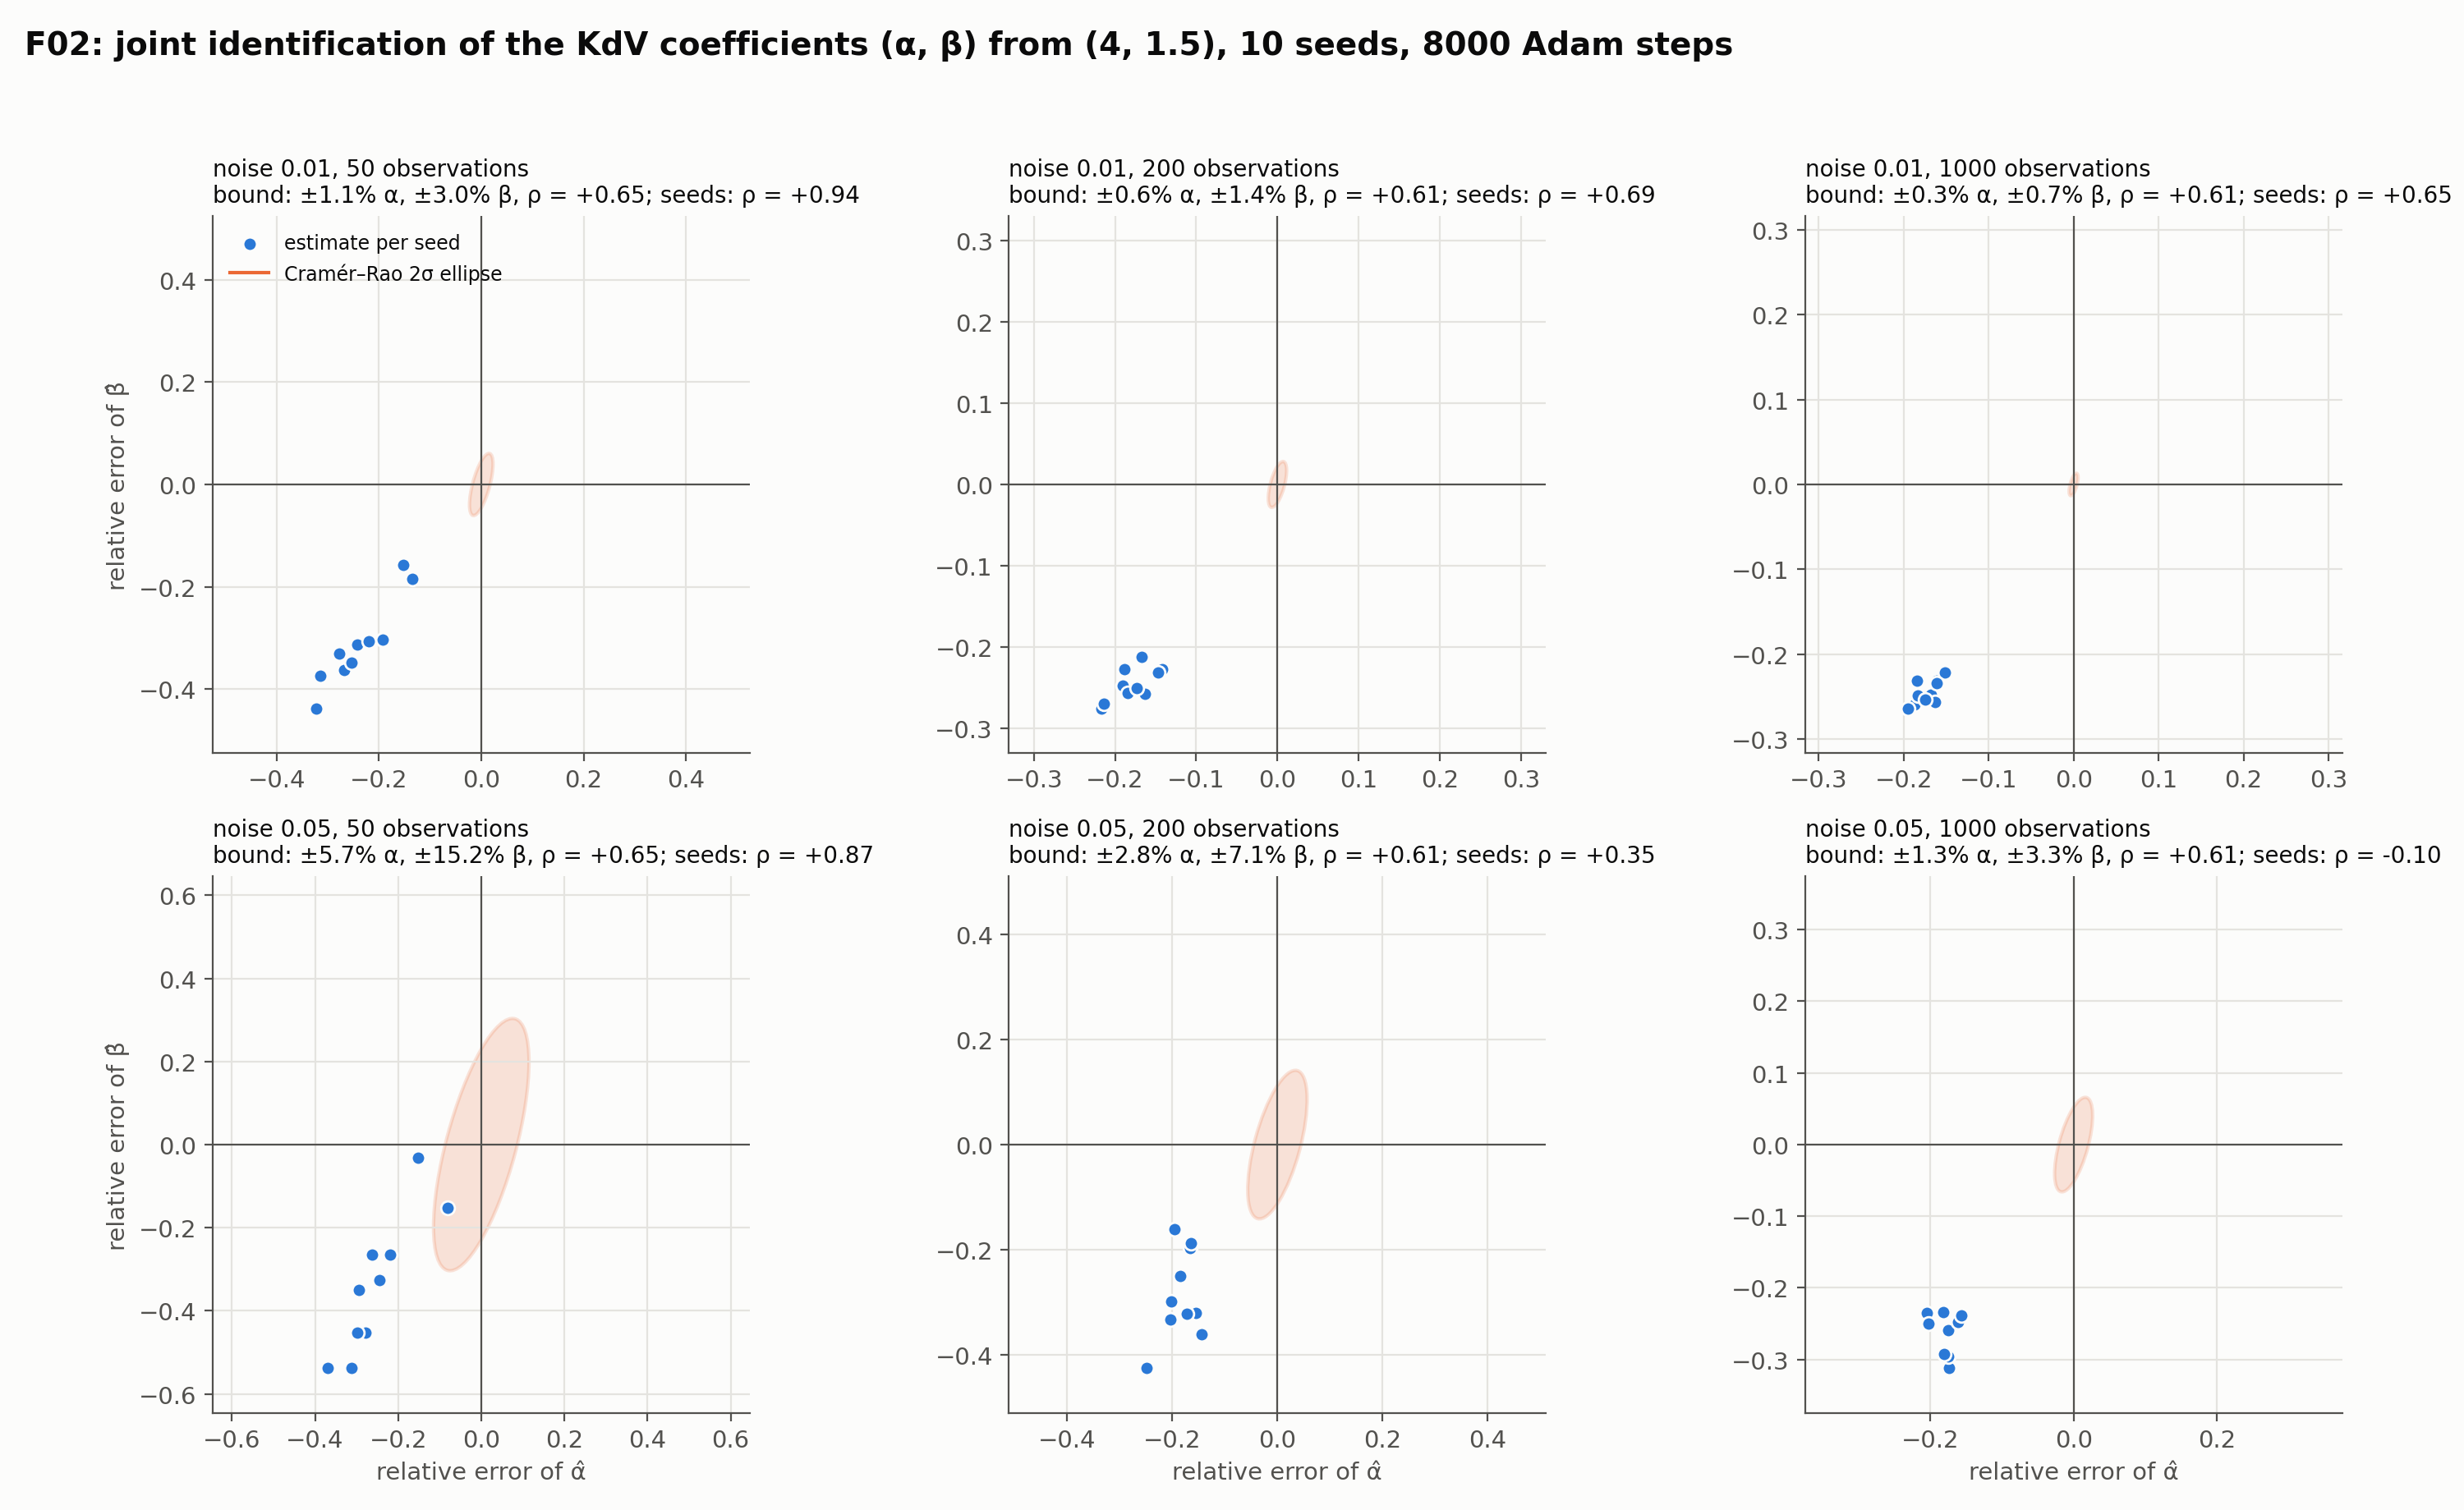

| noise | N | rel. error of α | rel. error of β | spread α / β | bound α / β | correlation seeds / bound | κ(F) | rel. L2 of u |
|---|---|---|---|---|---|---|---|---|
| 0.01 | 50 | 0.248 [0.199, 0.275] | 0.322 [0.304, 0.359] | 0.060 / 0.080 | 0.011 / 0.030 | +0.94 / +0.65 | 12.2 | 0.167 |
| 0.01 | 200 | 0.178 [0.164, 0.190] | 0.249 [0.229, 0.258] | 0.024 / 0.019 | 0.006 / 0.014 | +0.69 / +0.61 | 10.5 | 0.132 |
| 0.01 | 1000 | 0.171 [0.162, 0.184] | 0.248 [0.232, 0.255] | 0.013 / 0.013 | 0.003 / 0.007 | +0.65 / +0.61 | 11.0 | 0.120 |
| 0.05 | 50 | 0.271 [0.226, 0.298] | 0.339 [0.264, 0.453] | 0.079 / 0.157 | 0.057 / 0.152 | +0.87 / +0.65 | 12.2 | 0.213 |
| 0.05 | 200 | 0.179 [0.165, 0.200] | 0.309 [0.211, 0.330] | 0.029 / 0.080 | 0.028 / 0.071 | +0.35 / +0.61 | 10.5 | 0.157 |
| 0.05 | 1000 | 0.175 [0.166, 0.182] | 0.249 [0.241, 0.284] | 0.015 / 0.027 | 0.013 / 0.033 | -0.10 / +0.61 | 11.0 | 0.130 |

**Conclusion (from `experiments/F02_kdv_joint/README.md`)**


1. **The pair is identifiable from the data but not from this surrogate.** The bound says 200 clean points determine $\alpha$ to 0.6 % and $\beta$ to 1.4 %; the PINN returns them 18 % and 25 % low, with a spread across seeds of only 2 %. Every seed converges to the same wrong point, and a run *started at the truth drifts to it*: the minimum of the PINN loss is not at $(\alpha^\star, \beta^\star)$. This is the F01 surrogate floor (2 % for the heat equation) grown to 20 % for a third-order operator, and it is a property of the loss, not of the optimizer: three times the training changes nothing.
2. **What the surrogate trades.** The network cannot drive the third-derivative residual of the true soliton to zero with 4 × 64 tanh units, so the loss is minimized by a slightly wrong soliton whose equation has smaller $\alpha$ and $\beta$ (weaker nonlinearity and weaker dispersion, the same ratio $\alpha/\beta$). The field error of 12–17 % is the visible part of that trade; the data loss stays at the noise level (1.5e-4 against $\sigma^2 = 10^{-4}$), so the data are fitted, and the parameters are where the physics term is cheapest. Raising the data weight tenfold halves the bias and the field error, which confirms the mechanism: the estimate sits at the balance point of a soft physics term and a soft data term.
3. **The bound still predicts the scatter.** Where the surrogate bias is a constant offset, the spread across seeds follows the bound in both parameters and the correlation of the estimates is the predicted one (+0.65 vs +0.61 at $N = 1000$). The Fisher information describes the random part of the error even when a systematic part dominates it; it cannot see the systematic part, which is why K01 and the docs insist on reporting the field error next to it.
4. **Joint identification needs a resolved forward problem.** The order of business for two-parameter problems is: make the forward solve accurate (a network that resolves the third derivative, a likelihood-based data weight, an L-BFGS finish), check the field error, and only then read the Fisher ellipse. Items D01/D02 and K39 on the backlog are the enablers; F02 should be rerun after them.

**Consequences for the backlog:**
- K39 (data weight from the noise model) has its motivating case: the weight moves the estimate by 10 % here.
- D01/D02 (optimizer settling) and a K03-type check of the KdV residual conditioning come before any further KdV identification.
- The F02 cells with $N = 50$ at noise 0.01 show spreads 5× the bound and correlations near +0.9: with few points the surrogate's compromise varies with the draw, which is the regime where ensembles (F06) will be needed to report an honest interval.


In [15]:
runs = load("F02_kdv_joint")
if runs:
    figure("F02_kdv_joint", "f02_kdv_joint.png")
    rows = []
    for noise in sorted({r["noise"] for r in runs}):
        for n in sorted({r["n_obs"] for r in runs}):
            sel = [r for r in runs if r["noise"] == noise and r["n_obs"] == n]
            a = np.array([r["alpha_hat"] for r in sel]) / 6; b = np.array([r["beta_hat"] for r in sel])
            rows.append([noise, n, med_iqr([r["alpha_rel_error"] for r in sel]), med_iqr([r["beta_rel_error"] for r in sel]),
                         f"{a.std():.3f} / {b.std():.3f}",
                         f"{np.median([r['crlb_alpha_rel_std'] for r in sel]):.3f} / {np.median([r['crlb_beta_rel_std'] for r in sel]):.3f}",
                         f"{np.corrcoef(a, b)[0, 1]:+.2f} / {np.median([r['crlb_correlation'] for r in sel]):+.2f}",
                         f"{np.median([r['fisher_condition_number'] for r in sel]):.1f}", f"{np.median([r['l2_error'] for r in sel]):.3f}"])
    table(["noise", "N", "rel. error of α", "rel. error of β", "spread α / β", "bound α / β", "correlation seeds / bound", "κ(F)", "rel. L2 of u"], rows)
    readme("F02_kdv_joint")

## F03: Burgers viscosity near the shock

**The equation.** $u_t + u\, u_x = \nu\, u_{xx}$ on $[-1, 1] \times [0, 1]$ with $u(x, 0) = -\sin \pi x$ and $u(\pm 1, t) = 0$, at $\nu^\star = 0.01/\pi \approx 3.18 \times 10^{-3}$. The characteristics converge at $x = 0$ and a viscous shock of width $O(\nu)$ forms around $t \approx 0.3$. The viscosity acts almost only inside that shock, where $\partial u / \partial\nu$ reaches $\pm 146$; elsewhere it is near zero.

**Why $\log\nu$.** Adam's step is about $\eta = 10^{-3}$ per parameter per step, which is 30 % of $\nu^\star$: identifying $\nu$ directly would be unstable and could make it negative. The residual is therefore written as `u_t + u*u_x - exp(log_nu)*u_xx` and $\vartheta = \log\nu$ is identified: the step becomes relative, $\nu$ stays positive, and the sensitivities are related by

$$
\frac{\partial u}{\partial \vartheta} = \nu\, \frac{\partial u}{\partial \nu}, \qquad \frac{\operatorname{std}(\hat\nu)}{\nu} \approx \operatorname{std}(\hat\vartheta) .
$$

**The bound without a closed form.** There is no closed form for $\partial u / \partial\nu$, so it is taken by central differences of the Cole–Hopf reference solution, $\big(u_{\nu(1+h)} - u_{\nu(1-h)}\big) / (2 h \nu)$ with $h = 0.01$, on a 1601 × 161 grid. Observations are nodes of that grid, so no interpolation error enters. Because the sensitivity is concentrated in the shock, the bound of a random draw depends strongly on how many of its points fall inside it.

**Setup.** The F01 noise × count grid, started at $5\nu^\star$, 10,000 steps, 10 seeds.

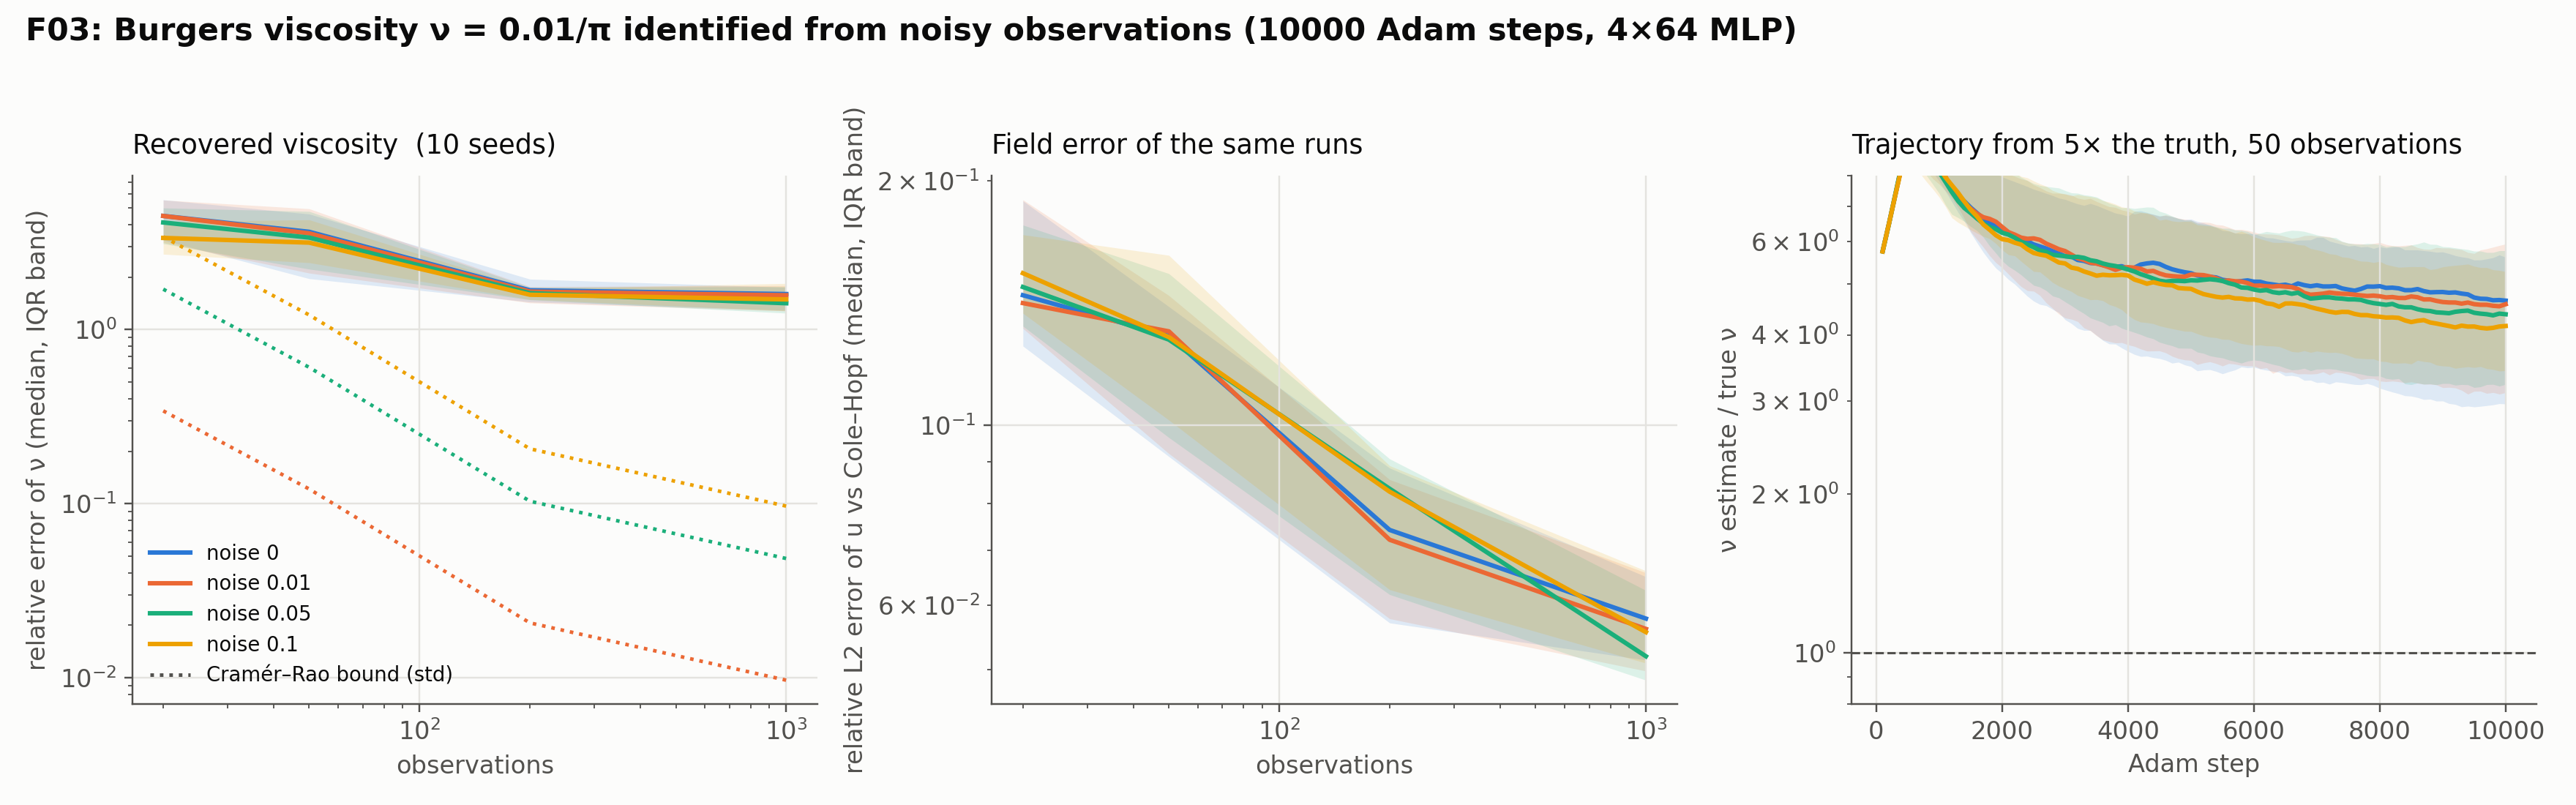

| noise σ | N | rel. error of ν, median [IQR] | spread across seeds | Cramér–Rao bound (median) | mean bias | rel. L2 of u |
|---|---|---|---|---|---|---|
| 0.0 | 20 | 4.496 [3.263, 5.565] | 1.790 | 0.000 | +4.626 | 0.144 |
| 0.0 | 50 | 3.643 [1.960, 4.608] | 1.656 | 0.000 | +3.599 | 0.129 |
| 0.0 | 200 | 1.680 [1.441, 1.948] | 0.394 | 0.000 | +1.740 | 0.074 |
| 0.0 | 1000 | 1.599 [1.291, 1.748] | 0.283 | 0.000 | +1.525 | 0.058 |
| 0.01 | 20 | 4.492 [3.160, 5.543] | 1.860 | 0.341 | +4.681 | 0.141 |
| 0.01 | 50 | 3.571 [2.110, 4.944] | 1.602 | 0.121 | +3.611 | 0.130 |
| 0.01 | 200 | 1.652 [1.423, 1.765] | 0.378 | 0.021 | +1.692 | 0.072 |
| 0.01 | 1000 | 1.574 [1.278, 1.789] | 0.304 | 0.010 | +1.550 | 0.056 |
| 0.05 | 20 | 4.122 [3.113, 4.994] | 1.945 | 1.705 | +4.484 | 0.148 |
| 0.05 | 50 | 3.375 [2.225, 4.773] | 1.475 | 0.607 | +3.564 | 0.127 |
| 0.05 | 200 | 1.619 [1.482, 1.749] | 0.342 | 0.103 | +1.683 | 0.083 |
| 0.05 | 1000 | 1.416 [1.242, 1.765] | 0.282 | 0.048 | +1.493 | 0.052 |
| 0.1 | 20 | 3.360 [2.709, 4.158] | 2.056 | 3.410 | +3.974 | 0.154 |
| 0.1 | 50 | 3.157 [2.421, 4.270] | 1.417 | 1.213 | +3.412 | 0.128 |
| 0.1 | 200 | 1.585 [1.489, 1.716] | 0.269 | 0.206 | +1.621 | 0.083 |
| 0.1 | 1000 | 1.489 [1.280, 1.840] | 0.289 | 0.097 | +1.550 | 0.056 |

**Conclusion (from `experiments/F03_burgers_nu/README.md`)**


1. **The viscosity is overestimated 2.5–5×, whatever the noise.** The error is a bias, and it is the same mechanism as the F01 floor and the F02 offset, in its extreme form: a 4 × 64 tanh network resolves a shock several times wider than the true one (width $O(\nu)$, i.e. about 0.003 on a domain of length 2), and a wider shock *is* the solution of Burgers at a larger viscosity. The physics term is satisfied best by the $\nu$ that matches the width the network can represent. K01 saw the same thing from the other side: the surrogate's sensitivity to $\nu$ is that of a smooth shock, not of the real one.
2. **Data help slowly, through the shock only.** The bias falls from 4.5× at 20 points to 1.6× at 1,000, and the estimate is still decreasing at 10,000 steps, because only observations inside the shock carry information about $\nu$ (the bound's sensitivity is near zero elsewhere) and only a few of 1,000 random points fall there. Dense sampling across the shock, which F05 would call a probe placed where the information is, is the data layout this problem needs.
3. **The bound is irrelevant until the bias is gone.** The Cramér–Rao bound is 1–10 % in most cells; the bias is 150–450 %. Nothing in the Fisher analysis predicts this, and nothing in it should: it is the surrogate's error, and it is detected by the field error (6–15 %, concentrated at the shock) and by the K01 comparison, not by the bound.
4. **Identifying $\log\nu$ did its job.** Every run stayed positive and stable from a 5× start, with Adam's relative step; the same runs with $\nu$ identified directly would have moved it by 30 % per step. The parametrization is now documented in the custom-equations guide.

**Consequences for the backlog:**
- Burgers viscosity identification needs a resolved shock before anything else: RAD sampling at the shock (the B01 work), a sharper or larger network, or the time-marching of H03/H04. F03 is rerun after that with the same driver.
- K32-type reference comparisons should report where the field error sits, not only its norm; a 6 % error at the shock is a 150 % error in $\nu$.
- The three identification problems now order the surrogate floor by operator and feature sharpness: heat 2 %, KdV soliton 20 %, Burgers shock 150 %. Paper P07 reports the three together.


In [16]:
runs = load("F03_burgers_nu")
if runs:
    figure("F03_burgers_nu", "f03_burgers_nu.png")
    nu = 0.01 / np.pi
    rows = []
    for noise in sorted({r["noise"] for r in runs}):
        for n in sorted({r["n_obs"] for r in runs}):
            sel = [r for r in runs if r["noise"] == noise and r["n_obs"] == n]
            v = np.array([r["nu_hat"] for r in sel])
            rows.append([noise, n, med_iqr([r["rel_error"] for r in sel]), f"{v.std() / nu:.3f}",
                         f"{np.median([r['crlb_rel_std'] for r in sel]):.3f}", f"{(v.mean() - nu) / nu:+.3f}", f"{np.median([r['l2_error'] for r in sel]):.3f}"])
    table(["noise σ", "N", "rel. error of ν, median [IQR]", "spread across seeds", "Cramér–Rao bound (median)", "mean bias", "rel. L2 of u"], rows)
    readme("F03_burgers_nu")

## F07: profile likelihood

**Definition.** The Fisher bound is a local, Gaussian statement. The profile likelihood is the honest check of practical identifiability: fix the parameter and re-optimize everything else,

$$
\mathrm{PL}(\alpha) \;=\; \min_{w}\ \sum_{i=1}^{N} \frac{\big(y_i - u_w(x_i, t_i;\, \alpha)\big)^2}{\sigma^2}
\qquad (= -2 \log L \text{ up to a constant}),
$$

where $u_w(\cdot;\alpha)$ is the network trained with $\alpha$ held fixed (physics + data, nothing trainable in the equation). For an identifiable parameter with Gaussian noise the profile is a parabola near its minimum,

$$
\mathrm{PL}(\alpha) - \mathrm{PL}(\hat\alpha) \;\approx\; F\, (\alpha - \hat\alpha)^2 ,
$$

and the set $\{\alpha : \mathrm{PL}(\alpha) - \mathrm{PL}(\hat\alpha) \le 3.84\}$ is a 95 % confidence interval. A flat profile means the data do not determine $\alpha$; an asymmetric one means the Gaussian error bar is wrong on one side.

**Setup.** The F01 data (200 observations, noise 0.05), $\alpha$ fixed at 0.7× to 1.3× the truth on nine values, 5,000 steps, 3 seeds. The same misfit evaluated with the *exact* solution at each $\alpha$ gives the profile the physics alone would produce; the gap between the two curves is the surrogate's contribution.

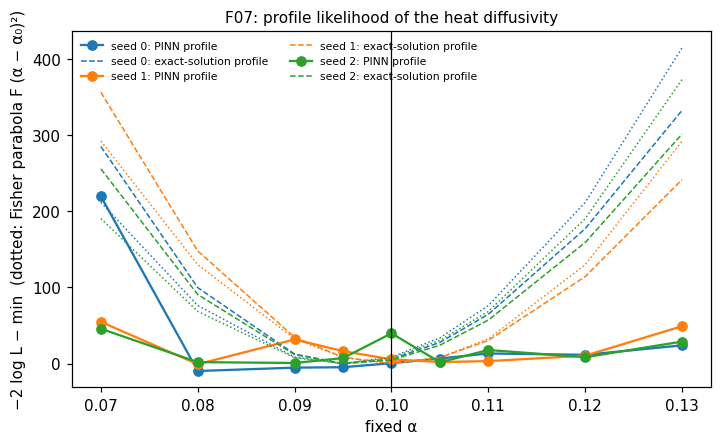

| fixed α | −2 log L, seed 0 | −2 log L, seed 1 | −2 log L, seed 2 |
|---|---|---|---|
| 0.070 | 449 | 243 | 253 |
| 0.080 | 219 | 188 | 210 |
| 0.090 | 224 | 220 | 208 |
| 0.095 | 224 | 205 | 215 |
| 0.100 | 230 | 194 | 247 |
| 0.105 | 236 | 191 | 209 |
| 0.110 | 242 | 192 | 225 |
| 0.120 | 241 | 199 | 216 |
| 0.130 | 253 | 238 | 236 |

**Conclusion (from `experiments/F07_profile_likelihood/README.md`)**


1. **The exact-solution profile is the Fisher parabola.** Its curvature equals $F$ to within 2 % on every seed and its minimum is at the truth to within half a grid step. This is an independent check of the Fisher formula used throughout F01–F05 and of `pinnrl.analysis.closed_form_bound`, from a misfit on a grid rather than from a derivative.
2. **The PINN profile is 2.5–12× flatter.** Trained with $\alpha$ clamped at a wrong value, the network does not reproduce the wrong solution; it deviates from the PDE, keeps fitting the data, and pays in residual (up to 9×). With a soft physics term the data misfit barely rises as $\alpha$ moves, so a profile read from it reports an interval several times too wide and a minimum biased low (0.08–0.09). The information the PINN-constrained model exposes is the curvature of the *total* weighted loss, not of the data term alone.
3. **Consistent with F01, not in conflict with it.** In the joint fit the parameter is free and moves to where the physics is cheapest, so the estimate's spread follows $F$; in the profile the parameter is clamped and the network absorbs the mismatch, so the data term cannot see $F$. F01 measures the estimator; F07 measures the identifiability the loss exposes, which for a PINN is governed by the physics weight.
4. **Profile likelihood with a PINN needs hard physics or the full loss.** Either enforce the equation hard enough that a wrong $\alpha$ costs misfit (a large residual weight, or hard constraints), or profile the total weighted loss and read it in the Bayesian frame where the weights are inverse variances. The same applies to every UQ method that reads curvature off the loss, including the Laplace approximation of roadmap item 5.

**Consequences for the backlog:**
- The Laplace approximation (K41) must use the full loss Hessian with its weights; its interval width depends on the physics weight, which K39 sets from the noise model.
- F07 is rerun with a larger residual weight and with hard initial and boundary constraints, to see how close the PINN profile can come to the Fisher parabola.
- The exact-solution profile is the reference for a two-dimensional profile of the KdV pair, where F02 found the surrogate's optimum displaced from the truth.


In [17]:
runs = load("F07_profile_likelihood")
if runs:
    grid = sorted({r["alpha"] for r in runs})
    seeds = sorted({r["seed"] for r in runs})
    fig, ax = plt.subplots(figsize=(7.5, 4.2))
    for s in seeds:
        sel = sorted([r for r in runs if r["seed"] == s], key=lambda r: r["alpha"])
        prof = np.array([r["neg2loglik"] for r in sel]); exact = np.array([r["neg2loglik_exact_solution"] for r in sel])
        F = sel[0]["fisher_information"]
        ax.plot(grid, prof - exact.min(), "o-", color=f"C{s}", label=f"seed {s}: PINN profile")
        ax.plot(grid, exact - exact.min(), "--", color=f"C{s}", linewidth=1, label=f"seed {s}: exact-solution profile")
        a0 = grid[int(np.argmin(exact))]
        ax.plot(grid, F * (np.array(grid) - a0) ** 2, ":", color=f"C{s}", linewidth=1)
    ax.axvline(0.1, color="black", linewidth=0.8)
    ax.set_xlabel("fixed α"); ax.set_ylabel("−2 log L − min  (dotted: Fisher parabola F (α − α₀)²)")
    ax.set_title("F07: profile likelihood of the heat diffusivity", fontsize=10)
    ax.legend(frameon=False, fontsize=7, ncol=2)
    plt.show()
    rows = [[f"{a:.3f}"] + [f"{[r for r in runs if r['seed'] == s and r['alpha'] == a][0]['neg2loglik']:.0f}" for s in seeds] for a in grid]
    table(["fixed α"] + [f"−2 log L, seed {s}" for s in seeds], rows)
    readme("F07_profile_likelihood")

## What the baseline says, in one place

- **The error of an identified parameter has two regimes:** a floor set by the surrogate's forward error that more data cannot lower (about 2 % for the heat diffusivity with this network and budget), and above it a near-efficient regime where the spread across noise draws matches the Cramér–Rao bound (F01, F05).
- **The Fisher information is a design tool.** It predicts how many observations a target accuracy needs and where to put a probe, before any training (F05: one probe at mid-domain beats 200 scattered points).
- **The initial guess is not a source of error** for a scalar parameter over two decades of starts (F04); the data realization is.
- **Field error does not predict parameter error** (F01): the relative L2 error of $u$ is 2–4 % everywhere while the parameter error spans 1.5 % to 22 %.
- **Follow-ups:** a noise-aware data weight (K39) for the low bias at few noisy points; optimizer settling (D01/D02) for the floor; the conditioning diagnostics in [notebook 07](07_conditioning.ipynb) for the cases where the surrogate, not the data, is the limit.